1. Загрузка изображения

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

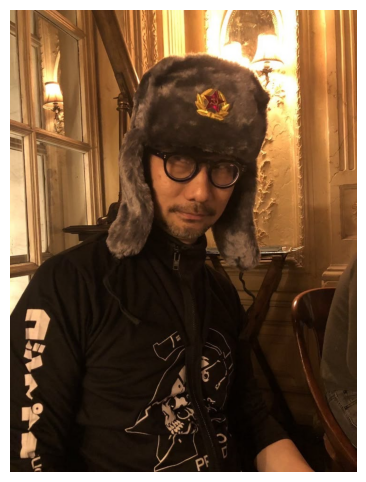

In [18]:
image = cv2.imread("image.jpg", cv2.IMREAD_COLOR_RGB)

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

2. Преобразование к полутоновому изображению двумя способами:
   1. Gray=0.3*R+0.59*G+0.11*B;     
   2. Gray=(R + G + B)/3,

In [14]:
def gray1(img):
    h, w, c = img.shape
    gr = np.zeros((h, w), dtype=np.uint8)

    for y in range(h):
        for x in range(w):
            r = int(img[y, x, 0])
            g = int(img[y, x, 1])
            b = int(img[y, x, 2])
            gr[y, x] = 0.3 * r + 0.59 * g + 0.11 * b

    return gr


def gray2(img):
    h, w, c = img.shape
    gr = np.zeros((h, w), dtype=np.uint8)

    for y in range(h):
        for x in range(w):
            r = int(img[y, x, 0])
            g = int(img[y, x, 1])
            b = int(img[y, x, 2])
            gr[y, x] = (r + g + b) / 3

    return gr

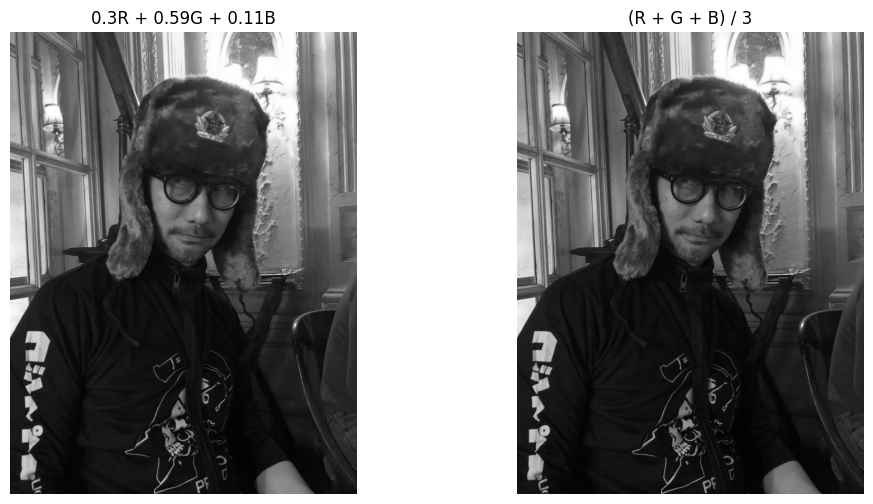

In [19]:
img1 = gray1(image)
img2 = gray2(image)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img1, cmap="gray", vmin=0, vmax=255)
plt.title("0.3R + 0.59G + 0.11B")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2, cmap="gray", vmin=0, vmax=255)
plt.title("(R + G + B) / 3")
plt.axis("off")

plt.show()

3. Получить разность этих полутоновых изображений

In [20]:
def diff_img(a, b):
    h, w = a.shape
    diff = np.zeros((h, w), dtype=np.uint8)

    for y in range(h):
        for x in range(w):
            diff[y, x] = abs(int(a[y, x]) - int(b[y, x]))

    return diff

Максимальная разность: 26
Средняя разность: 4.85


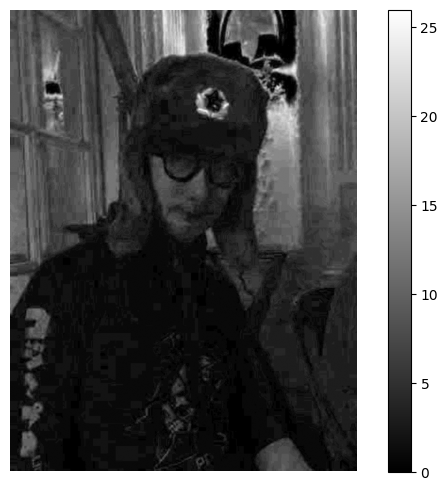

In [21]:
diff = diff_img(img1, img2)

print("Максимальная разность:", diff.max())
print(f"Средняя разность: {diff.mean():.2f}")

plt.figure(figsize=(8, 6))
plt.imshow(diff, cmap="gray")
plt.colorbar()
plt.axis("off")
plt.show()

4. Взять фрагмент видео и покадрово обрабатывать:
   1. преобразовывать к полутоновому
   2. получать разность между соседними кадрами,. Типа примитивнейший датчик движения))

In [23]:
video_path = "video.mp4"
diff_video_path = "video_diff.mp4"

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise FileNotFoundError(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
src_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
src_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frames_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

w = 480
h = src_h * w // src_w

video_codec = cv2.VideoWriter_fourcc(*"mp4v")
video_writer = cv2.VideoWriter(diff_video_path, video_codec, fps, (w, h))

step = max(frames_count // 5, 1)
prev_gray = None
motion = []
samples = []
n_frame = 0

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame = cv2.resize(frame, (w, h))
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        gray_frame = gray1(rgb_frame)

        if prev_gray is not None:
            diff_frame = diff_img(gray_frame, prev_gray)
            motion.append(diff_frame.mean())
            video_writer.write(cv2.cvtColor(diff_frame, cv2.COLOR_GRAY2BGR))

            if n_frame % step == 0 and len(samples) < 4:
                samples.append((n_frame, gray_frame, diff_frame))

        prev_gray = gray_frame
        n_frame += 1
finally:
    cap.release()
    video_writer.release()

print(n_frame, frames_count)
print(f"Video duration: {n_frame / fps:.2f} sec")

25 25
Video duration: 1.00 sec


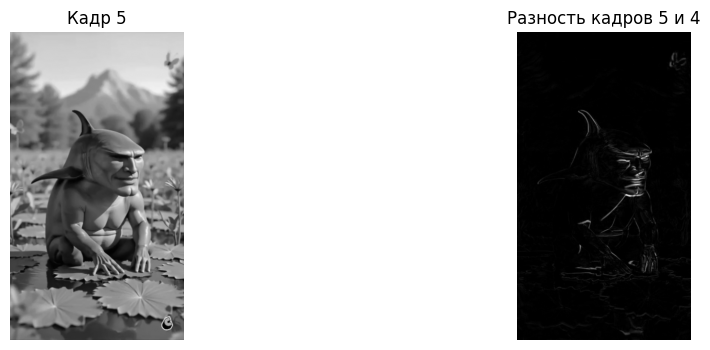

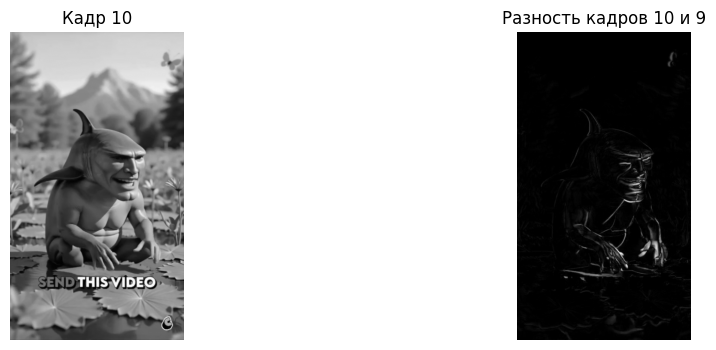

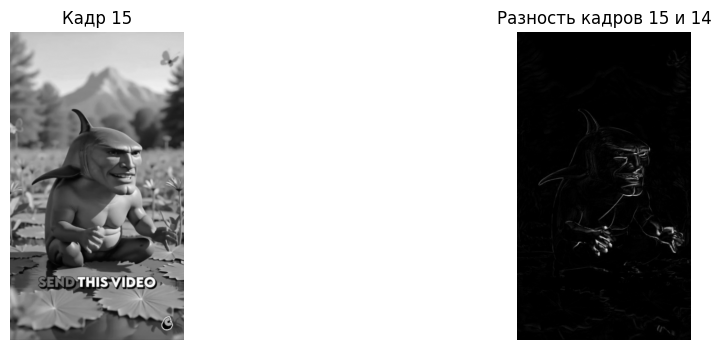

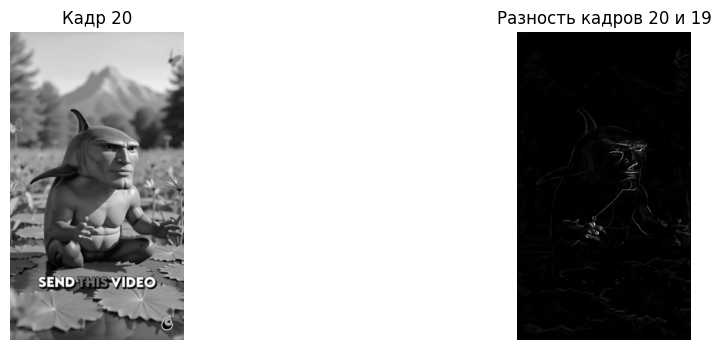

In [24]:
for n, gray_frame, diff_frame in samples:
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(gray_frame, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Кадр {n}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(diff_frame, cmap="gray")
    plt.title(f"Разность кадров {n} и {n - 1}")
    plt.axis("off")

plt.show()

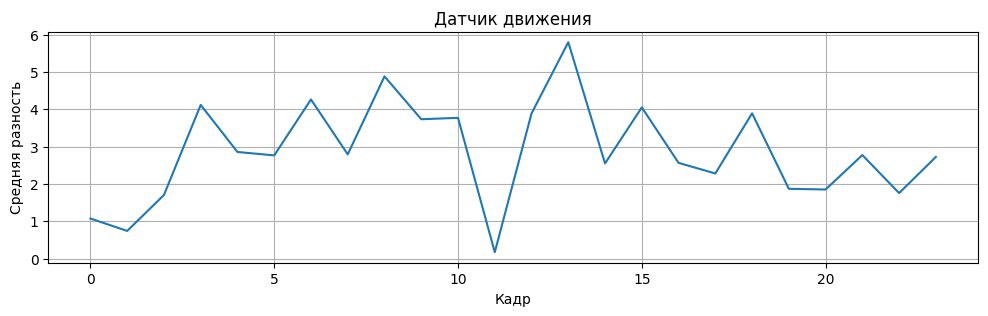

In [25]:
plt.figure(figsize=(12, 3))
plt.plot(motion)
plt.xlabel("Кадр")
plt.ylabel("Средняя разность")
plt.title("Датчик движения")
plt.grid()
plt.show()